In [2]:
import pandas as pd
from pathlib import Path

# Calculate the percentage of customers who churn in each contract type
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))


NameError: name 'df_clean' is not defined

In [5]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_clean = pd.read_csv(
    "C:/Users/main/Desktop/Projects/Customer Churn Prediction System/data/cleaned_customer_churn.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df_clean.shape)


Dataset loaded successfully!
Shape: (7043, 21)


In [6]:

contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))


Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


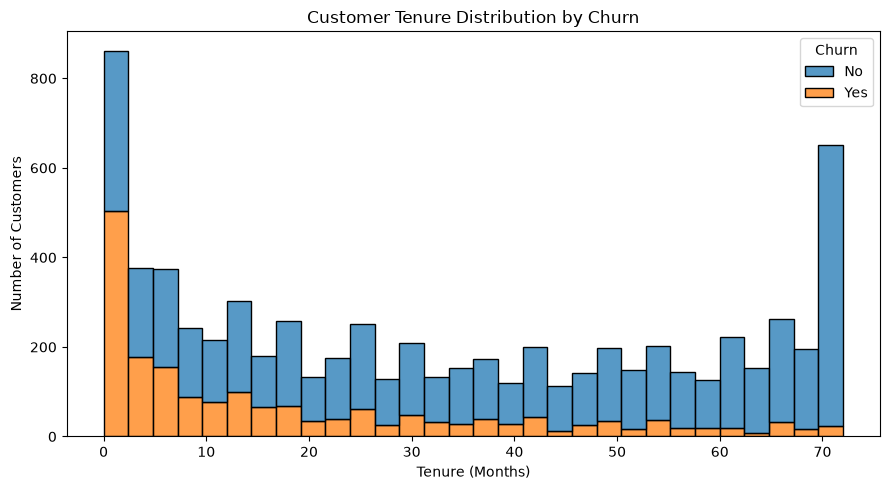

In [7]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


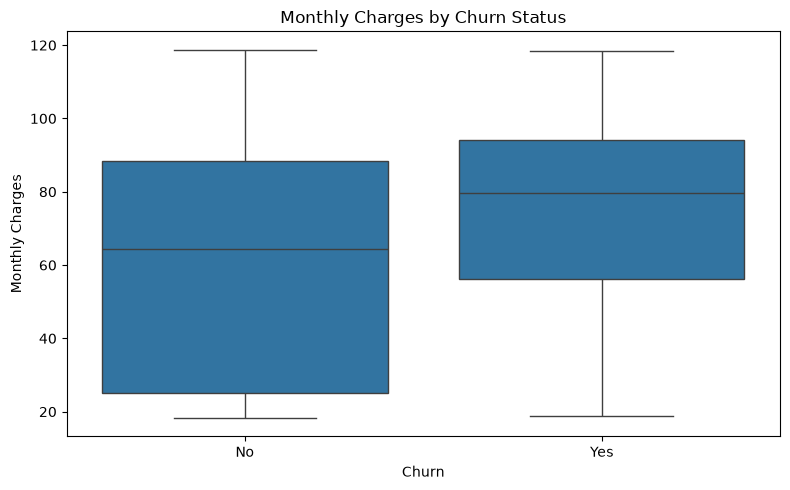

In [8]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()


In [9]:

features = [
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling"
]

for feature in features:
    churn_rate = (
        df_clean.groupby(feature, observed=False)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\nChurn rate by {feature} (%):")
    print(churn_rate.round(2))



Churn rate by InternetService (%):
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

Churn rate by PaymentMethod (%):
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

Churn rate by PaperlessBilling (%):
PaperlessBilling
Yes    33.57
No     16.33
Name: Churn, dtype: float64


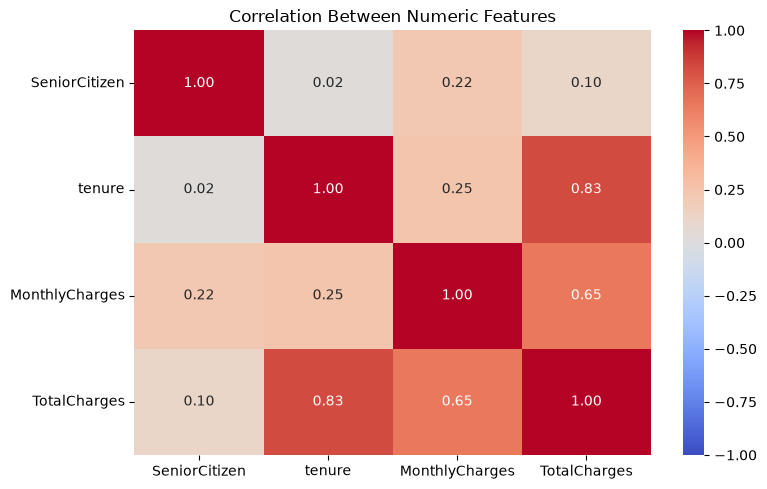

In [10]:

numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation = df_clean[numeric_cols].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()
